# Serie II: sensor virtual con señales actuales

Se estima `ZZQBCHLL` contemporáneo con otros sensores recibidos hasta ese instante. Por petición del usuario se eliminó la ingeniería de memoria del código y se comparan **29 señales actuales frente a 15**, sin objetivo ni historial del objetivo como entradas. Los retardos solicitados por el PDF quedan pendientes de un trabajo específico; no se dan por resueltos con este experimento.

Se mantienen Ridge, bosque e HistGradientBoosting y referencia mediana. La versión reducida se elige con Ridge dentro de cada entrenamiento. **Esta revisión se decidió después de observar el test de la versión anterior**: el último día se reporta como comprobación temporal reutilizada y exploratoria, no como test independiente intacto. La regla de selección actual usa exclusivamente las tres validaciones; no se retoca a partir de esa comprobación. Alcance físico y disponibilidad en [el documento de contexto](../docs/serie2-significado-disponibilidad.md).


In [1]:
from pathlib import Path
import json
import sys

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from threadpoolctl import threadpool_limits

raiz = next(p for p in [Path.cwd(), Path.cwd().parent] if (p / "scripts/modelado_serie2.py").exists())
sys.path.insert(0, str(raiz))
from scripts.modelado_serie2 import (
    OBJETIVO, crear_modelos, seleccionar_variables, calcular_metricas,
)

datos = pd.read_csv(raiz / "data/raw/serie2/data.csv", parse_dates=["date"])
salida = raiz / "outputs"
salida.mkdir(exist_ok=True)
assert datos.date.is_unique and datos.date.is_monotonic_increasing
assert datos.date.diff().dropna().eq(pd.Timedelta(seconds=5)).all()
assert datos[OBJETIVO].notna().all()
assert np.isfinite(datos.drop(columns="date").to_numpy()[~datos.drop(columns="date").isna()]).all()
inicio = datos.date.iloc[0]


## Diseño de comparación

- Cinco bloques consecutivos de 24 horas desde el primer timestamp. Entrenamiento expansivo: día 1 → 2; días 1–2 → 3; días 1–3 → 4. Día 5: comprobación reutilizada, ya observada en el experimento anterior.
- Separación de cinco minutos entre etiquetas de entrenamiento y evaluación para reducir vecindad inmediata, sin afirmar independencia. No hay arranque de historia porque solo se usan valores actuales.
- Rejilla de modelado de diez segundos: primer registro de cada pareja del objetivo repetido. La fase no prueba el instante físico de actualización; se conserva el resto con motivo, sin declararlo inválido.
- Mismas fechas para ambas variantes. Medianas de imputación, escalado y selección se ajustan solo con entrenamiento. Los valores extremos y la válvula estable se conservan.
- MAE medio de las tres validaciones como criterio principal; RMSE, R², sesgo, WAPE y p95 como diagnósticos. WAPE es error absoluto agregado / caudal observado agregado, no MAPE ni MAE porcentual. Unidad física del caudal sin confirmar.
- Regla de parsimonia conservada: entre candidatos a ≤1 % del MAE mínimo y peor MAE diario a ≤5 % del peor día del mínimo, preferir menos entradas y luego Ridge. Son tolerancias técnicas exploratorias, no de negocio. Sin búsqueda adicional de hiperparámetros.


In [2]:
base = datos.columns.drop(["date", OBJETIVO]).tolist()
assert len(base) == 29
assert datos[OBJETIVO].iloc[::2].reset_index(drop=True).equals(datos[OBJETIVO].iloc[1::2].reset_index(drop=True))
fase = np.arange(len(datos)) % 2 == 0
fuera_modelado = datos.loc[~fase].copy()
fuera_modelado["motivo"] = "Segunda lectura del par; fuera de rejilla de modelado, sin declararla inválida"
fuera_modelado.to_csv(salida / "serie2_filas_fuera_modelado.csv", index=False)
X = datos.loc[fase, base].reset_index(drop=True)
y = datos.loc[fase, OBJETIVO].reset_index(drop=True)
fechas = datos.loc[fase, "date"].reset_index(drop=True)
assert not any(OBJETIVO in columna or "__" in columna for columna in X)
print(f"Original: {len(datos):,}; modelado: {len(X):,}; fuera de rejilla: {len(fuera_modelado):,}")

pliegues = []
tabla_particiones = []
for dia in [1, 2, 3, 4]:
    limite = inicio + pd.Timedelta(days=dia)
    entrenamiento = fechas.lt(limite - pd.Timedelta(minutes=5))
    evaluacion = fechas.ge(limite) & fechas.lt(limite + pd.Timedelta(days=1))
    nombre = f"Validación {dia}" if dia < 4 else "Comprobación reutilizada"
    assert fechas[entrenamiento].max() < fechas[evaluacion].min() - pd.Timedelta(minutes=5)
    tabla_particiones.append({
        "particion": nombre, "n_entrenamiento": int(entrenamiento.sum()), "n_evaluacion": int(evaluacion.sum()),
        "inicio_entrenamiento": fechas[entrenamiento].min(), "fin_entrenamiento": fechas[entrenamiento].max(),
        "inicio_evaluacion": fechas[evaluacion].min(), "fin_evaluacion": fechas[evaluacion].max(),
    })
    if dia < 4:
        pliegues.append((nombre, entrenamiento, evaluacion))
    else:
        desarrollo, test = entrenamiento, evaluacion
primer_entrenamiento = pliegues[0][1]
tabla_particiones = pd.DataFrame(tabla_particiones)
tabla_particiones.to_csv(salida / "serie2_particiones.csv", index=False)
display(tabla_particiones)


Original: 86,400; modelado: 43,200; fuera de rejilla: 43,200


,particion,n_entrenamiento,n_evaluacion,inicio_entrenamiento,fin_entrenamiento,inicio_evaluacion,fin_evaluacion
0,Validación 1,8610,8640,2022-03-27 14:28:54,2022-03-28 14:23:44,2022-03-28 14:28:54,2022-03-29 14:28:44
1,Validación 2,17250,8640,2022-03-27 14:28:54,2022-03-29 14:23:44,2022-03-29 14:28:54,2022-03-30 14:28:44
2,Validación 3,25890,8640,2022-03-27 14:28:54,2022-03-30 14:23:44,2022-03-30 14:28:54,2022-03-31 14:28:44
3,Comprobación reutilizada,34530,8640,2022-03-27 14:28:54,2022-03-31 14:23:44,2022-03-31 14:28:54,2022-04-01 14:28:44


## Selección de quince y competencia

Se aplica eliminación recursiva de variables (RFE) con Ridge alpha=100 y entradas estandarizadas. En cada entrenamiento se retira una señal de menor coeficiente absoluto y se reajusta Ridge, hasta conservar exactamente quince. La magnitud depende de colinealidad y regularización; no es un efecto causal. No se usa el ranking de un bosque para seleccionar entradas de Ridge. Tampoco se elimina automáticamente un miembro de cada pareja correlacionada: su contraste puede contener información conjunta.

Los quince pueden cambiar entre pliegues, y se vuelven a seleccionar al ajustar en desarrollo. Se guardan conjuntos y posiciones RFE (posición 1 significa retenida, sin ordenar entre las quince). Se reentrenan los tres algoritmos con 29 y 15 entradas en las mismas fechas. El criterio se orienta a Ridge; los otros dos son comparadores, no selecciones óptimas específicas para cada algoritmo.

Referencia: [RFE en scikit-learn](https://scikit-learn.org/1.6/modules/generated/sklearn.feature_selection.RFE.html).


In [3]:
resultados = []
posiciones = []
selecciones = []
predicciones_validacion = []
for nombre_pliegue, entrenar, validar in pliegues:
    with threadpool_limits(limits=2):
        reducidas, posiciones_pliegue = seleccionar_variables(X.loc[entrenar], y[entrenar])
        posiciones.extend({"particion": nombre_pliegue, "sensor": sensor, "posicion_RFE": int(valor)} for sensor, valor in posiciones_pliegue.items())
        selecciones.extend({"particion": nombre_pliegue, "entrada": columna} for columna in reducidas)
        for variante, columnas in {"Base 29": base, "Reducida 15": reducidas}.items():
            for nombre_modelo, modelo in crear_modelos().items():
                modelo.fit(X.loc[entrenar, columnas], y[entrenar])
                estimado = modelo.predict(X.loc[validar, columnas])
                resultados.append({
                    "particion": nombre_pliegue, "variante": variante, "modelo": nombre_modelo,
                    "n_entradas": len(columnas), "n_sensores": len(columnas),
                    **calcular_metricas(y[validar], estimado),
                })
                predicciones_validacion.append(pd.DataFrame({
                    "date": fechas[validar], "observado": y[validar], "estimado": estimado,
                    "particion": nombre_pliegue, "variante": variante, "modelo": nombre_modelo,
                }))
                print(nombre_pliegue, variante, nombre_modelo, f"MAE={resultados[-1]['MAE']:.4f}", flush=True)
        resultados.append({
            "particion": nombre_pliegue, "variante": "Referencia", "modelo": "Mediana entrenamiento",
            "n_entradas": 0, "n_sensores": 0,
            **calcular_metricas(y[validar], np.full(validar.sum(), y[entrenar].median())),
        })
    pd.DataFrame(resultados).to_csv(salida / "serie2_validacion.csv", index=False)
tabla_validacion = pd.DataFrame(resultados)
tabla_selecciones = pd.DataFrame(selecciones)
pd.DataFrame(posiciones).to_csv(salida / "serie2_posiciones_rfe.csv", index=False)
tabla_selecciones.to_csv(salida / "serie2_selecciones_por_pliegue.csv", index=False)
pd.concat(predicciones_validacion).to_csv(salida / "serie2_predicciones_validacion.csv", index=False)
resumen = tabla_validacion.groupby(["variante", "modelo"], as_index=False).agg(
    MAE_medio=("MAE", "mean"), MAE_peor_dia=("MAE", "max"), RMSE_medio=("RMSE", "mean"),
    R2_medio=("R2", "mean"), sesgo_medio=("sesgo", "mean"),
    entradas_medias=("n_entradas", "mean"), sensores_medios=("n_sensores", "mean"),
)
resumen.to_csv(salida / "serie2_resumen_validacion.csv", index=False)
display(resumen.sort_values("MAE_medio").round(5))
display(tabla_selecciones.groupby("entrada").particion.nunique().sort_values(ascending=False).rename("pliegues_retenida").to_frame())


Validación 1 Base 29 Ridge MAE=0.5141


Validación 1 Base 29 Bosque aleatorio MAE=0.9400


Validación 1 Base 29 HistGradientBoosting MAE=0.7918


Validación 1 Reducida 15 Ridge MAE=0.5159


Validación 1 Reducida 15 Bosque aleatorio MAE=0.9271


...

Validación 3 Reducida 15 Ridge MAE=0.3715


Validación 3 Reducida 15 Bosque aleatorio MAE=0.8304


Validación 3 Reducida 15 HistGradientBoosting MAE=0.6425


,variante,modelo,MAE_medio,MAE_peor_dia,RMSE_medio,R2_medio,sesgo_medio,entradas_medias,sensores_medios
5,Reducida 15,Ridge,0.45728,0.51595,0.58625,0.93955,0.06520,15.0,15.0
2,Base 29,Ridge,0.46220,0.51411,0.59253,0.93863,0.02955,29.0,29.0
4,Reducida 15,HistGradientBoosting,0.76396,0.88668,1.01908,0.82892,0.13745,15.0,15.0
1,Base 29,HistGradientBoosting,0.77495,0.88239,1.03555,0.82220,0.12685,29.0,29.0
3,Reducida 15,Bosque aleatorio,0.94300,1.07148,1.23237,0.75109,0.20836,15.0,15.0
0,Base 29,Bosque aleatorio,0.95499,1.07524,1.24843,0.74480,0.19957,29.0,29.0
6,Referencia,Mediana entrenamiento,2.04332,2.30464,2.58728,-0.07311,0.01738,0.0,0.0


,pliegues_retenida
entrada,
AIR_8301A.AV_0#,3
PTCA_8322A.AV_0#,3
PT_8313D.AV_0#,3
PTCA_8324.AV_0#,3
TE_8313B.AV_0#,3
YJJWSLL.AV_0#,3
PT_8313F.AV_0#,3
SXLTCYY.AV_0#,3
YFJ3_AI.AV_0#,3


In [4]:
candidatos = resumen.loc[resumen.variante.ne("Referencia")].copy()
mejor = candidatos.loc[candidatos.MAE_medio.idxmin()]
comparables = candidatos.loc[
    candidatos.MAE_medio.le(mejor.MAE_medio * 1.01)
    & candidatos.MAE_peor_dia.le(mejor.MAE_peor_dia * 1.05)
].copy()
comparables["orden_modelo"] = comparables.modelo.map({"Ridge": 0, "Bosque aleatorio": 1, "HistGradientBoosting": 2})
elegido = comparables.sort_values(["entradas_medias", "orden_modelo", "MAE_medio", "variante"]).iloc[0]
decision = {
    "modelo": elegido.modelo, "variante": elegido.variante,
    "MAE_validacion": float(elegido.MAE_medio), "peor_MAE_validacion": float(elegido.MAE_peor_dia),
    "criterio": "MAE de validación con regla de parsimonia; comprobación final reutilizada",
    "evaluacion_final_independiente": False,
}
(salida / "serie2_decision_antes_test.json").write_text(json.dumps(decision, ensure_ascii=False, indent=2, allow_nan=False), encoding="utf-8")
print(json.dumps(decision, ensure_ascii=False, indent=2))


{
  "modelo": "Ridge",
  "variante": "Reducida 15",
  "MAE_validacion": 0.45727929914873117,
  "peor_MAE_validacion": 0.5159481595961493,
  "criterio": "MAE de validación con regla de parsimonia; comprobación final reutilizada",
  "evaluacion_final_independiente": false
}


## Reajuste y comprobación temporal reutilizada

Se congela la elección de validación antes de recalcular el último día, que ya fue observado anteriormente. Se reentrena el campeón en desarrollo, incluida selección si corresponde, y se reporta con la referencia. La elección no cambia al ver estos errores. Es evidencia exploratoria de este archivo; confirmar generalización requiere un periodo adicional que no haya intervenido en la revisión.


In [5]:
columnas_finales = base
with threadpool_limits(limits=2):
    if decision["variante"] == "Reducida 15":
        columnas_finales, _ = seleccionar_variables(X.loc[desarrollo], y[desarrollo])
    campeon = crear_modelos()[decision["modelo"]].fit(X.loc[desarrollo, columnas_finales], y[desarrollo])
    estimado_test = campeon.predict(X.loc[test, columnas_finales])
referencia_test = np.full(test.sum(), y[desarrollo].median())
tabla_test = pd.DataFrame([
    {"modelo": decision["modelo"], "variante": decision["variante"], **calcular_metricas(y[test], estimado_test)},
    {"modelo": "Mediana entrenamiento", "variante": "Referencia", **calcular_metricas(y[test], referencia_test)},
])
tabla_test.to_csv(salida / "serie2_metricas_test.csv", index=False)
predicciones_test = pd.DataFrame({"date": fechas[test], "observado": y[test], "estimado": estimado_test, "referencia": referencia_test})
predicciones_test["error"] = predicciones_test.estimado - predicciones_test.observado
predicciones_test.to_csv(salida / "serie2_predicciones_test.csv", index=False)
pd.Series(columnas_finales, name="entrada").to_csv(salida / "serie2_entradas_campeon.csv", index=False)
joblib.dump({"modelo": campeon, "columnas": columnas_finales, "decision": decision}, salida / "serie2_sensor_virtual.joblib")
display(tabla_test.round(4))
print(f"Campeón: {decision['modelo']} / {decision['variante']}; {len(columnas_finales)} entradas")

# Diagnóstico por bloques horarios, sin reajustar el modelo ni la selección.
predicciones_test["bloque_6h"] = ((predicciones_test.date - (inicio + pd.Timedelta(days=4))).dt.total_seconds() // 21600).astype(int) + 1
por_tramo_test = pd.DataFrame([
    {"bloque_6h": bloque, "filas": len(tramo), **calcular_metricas(tramo.observado, tramo.estimado)}
    for bloque, tramo in predicciones_test.groupby("bloque_6h")
])
por_tramo_test.to_csv(salida / "serie2_metricas_test_por_tramo.csv", index=False)
display(por_tramo_test.round(4))


,modelo,variante,MAE,RMSE,R2,sesgo,WAPE_pct,error_abs_p95
0,Ridge,Reducida 15,0.3378,0.4234,0.9625,-0.0901,0.5564,0.8335
1,Mediana entrenamiento,Referencia,1.8936,2.4297,-0.2338,-1.0577,3.1186,4.4000


Campeón: Ridge / Reducida 15; 15 entradas


,bloque_6h,filas,MAE,RMSE,R2,sesgo,WAPE_pct,error_abs_p95
0,1,2160,0.3348,0.4193,0.9685,-0.0625,0.5384,0.8225
1,2,2160,0.3258,0.4057,0.8852,-0.0867,0.5560,0.7908
2,3,2160,0.3659,0.4569,0.8968,-0.1705,0.6070,0.9115
3,4,2160,0.3248,0.4100,0.9182,-0.0407,0.5256,0.7942


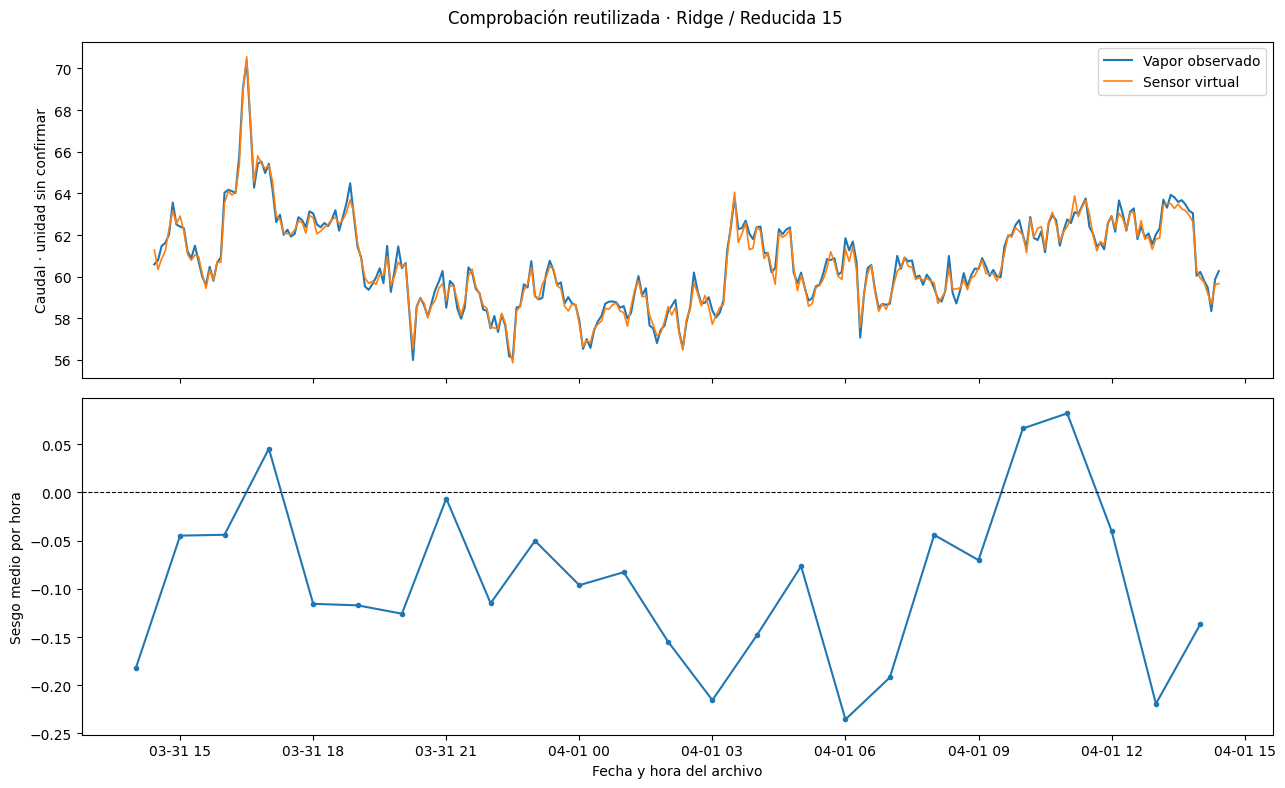

In [6]:
fig, ejes = plt.subplots(2, 1, figsize=(13, 8), sharex=True)
# Medianas de cinco minutos solo para visualizar; métricas sobre la rejilla de diez segundos.
vista = predicciones_test.set_index("date")[["observado", "estimado"]].resample("5min").median()
ejes[0].plot(vista.index, vista.observado, label="Vapor observado", linewidth=1.5)
ejes[0].plot(vista.index, vista.estimado, label="Sensor virtual", linewidth=1.2)
ejes[0].set_ylabel("Caudal · unidad sin confirmar")
ejes[0].legend()
error_horario = predicciones_test.set_index("date").error.resample("1h").mean()
ejes[1].plot(error_horario.index, error_horario, marker="o", markersize=3)
ejes[1].axhline(0, color="black", linestyle="--", linewidth=0.8)
ejes[1].set_ylabel("Sesgo medio por hora")
ejes[1].set_xlabel("Fecha y hora del archivo")
fig.suptitle(f"Comprobación reutilizada · {decision['modelo']} / {decision['variante']}")
fig.tight_layout()
fig.savefig(salida / "serie2_sensor_virtual_test.png", dpi=140, bbox_inches="tight")
plt.show()


## Interpretación

La tabla de coeficientes estandarizados permite examinar el aporte condicional de cada señal para Ridge, sin atribuir causalidad. Con predictores correlacionados, mantener los demás constantes puede describir una situación física poco plausible. Se revisa además el contraste numérico entre dos presiones solo en primer entrenamiento; sin unidades/ubicaciones confirmadas no se declara una caída física calibrada. No se añade como característica nueva.


In [7]:
assert decision["modelo"] == "Ridge", "Actualizar interpretación si cambia el ganador al modificar el experimento."
coeficientes = pd.DataFrame({
    "entrada": columnas_finales, "coeficiente_estandarizado": campeon[-1].coef_,
    "coeficiente_escala_original": campeon[-1].coef_ / campeon[1].scale_,
}).sort_values("coeficiente_estandarizado", key=lambda columna: columna.abs(), ascending=False)
coeficientes.to_csv(salida / "serie2_coeficientes_ridge.csv", index=False)
display(coeficientes.round(5))
presion_a, presion_b = "PTCA_8322A.AV_0#", "PTCA_8324.AV_0#"
diagnostico_presiones = pd.Series({
    "presion_a_con_vapor": X.loc[primer_entrenamiento, presion_a].corr(y[primer_entrenamiento]),
    "presion_b_con_vapor": X.loc[primer_entrenamiento, presion_b].corr(y[primer_entrenamiento]),
    "contraste_a_menos_b_con_vapor": (X.loc[primer_entrenamiento, presion_a] - X.loc[primer_entrenamiento, presion_b]).corr(y[primer_entrenamiento]),
}, name="correlacion_solo_primer_entrenamiento")
display(diagnostico_presiones.to_frame().round(5))
diagnostico_presiones.to_csv(salida / "serie2_diagnostico_presiones.csv")

from IPython.display import Markdown
mae_base = resumen.loc[resumen.modelo.eq("Ridge") & resumen.variante.eq("Base 29"), "MAE_medio"].iloc[0]
mae_reducida = resumen.loc[resumen.modelo.eq("Ridge") & resumen.variante.eq("Reducida 15"), "MAE_medio"].iloc[0]
display(Markdown(
    f"**Ridge: 29 frente a 15 entradas actuales.** MAE medio de validación: {mae_base:.5f} y {mae_reducida:.5f}. "
    f"Cambio relativo al reducir: {100 * (mae_reducida / mae_base - 1):+.2f} %. "
    f"Campeón según regla declarada: {decision['modelo']} / {decision['variante']}. "
    f"Comprobación reutilizada: MAE {tabla_test.MAE.iloc[0]:.5f}, R² {tabla_test.R2.iloc[0]:.5f}, "
    f"WAPE {tabla_test.WAPE_pct.iloc[0]:.4f} % y sesgo {tabla_test.sesgo.iloc[0]:.5f}. "
    "No es un test independiente de esta revisión."
))


,entrada,coeficiente_estandarizado,coeficiente_escala_original
3,PTCA_8322A.AV_0#,4.60224,59.98976
4,PTCA_8324.AV_0#,-4.43913,-58.70088
5,TE_8313B.AV_0#,0.41959,0.03912
14,YJJWSLL.AV_0#,0.36585,1.07978
2,PT_8313F.AV_0#,-0.16993,-0.00305
7,TV_8329ZC.AV_0#,0.16689,0.03404
9,AIR_8301A.AV_0#,-0.11898,-0.35264
10,AIR_8301B.AV_0#,0.10454,0.27252
1,PT_8313D.AV_0#,0.09896,0.00188
6,TE_8304.AV_0#,0.09820,0.03055


,correlacion_solo_primer_entrenamiento
presion_a_con_vapor,0.32717
presion_b_con_vapor,0.09984
contraste_a_menos_b_con_vapor,0.91318


**Ridge: 29 frente a 15 entradas actuales.** MAE medio de validación: 0.46220 y 0.45728. Cambio relativo al reducir: -1.06 %. Campeón según regla declarada: Ridge / Reducida 15. Comprobación reutilizada: MAE 0.33784, R² 0.96252, WAPE 0.5564 % y sesgo -0.09007. No es un test independiente de esta revisión.

## Alcance y pendientes

El campeón es exploratorio, no una autorización para controlar la caldera ni una certificación instrumental. La utilidad observada es estimación del vapor; no se cuantifica ahorro económico. Cinco días y muestras autocorrelacionadas no demuestran robustez amplia; faltan unidades, latencias, calidad, fórmula de compensación y prueba de disponibilidad independiente durante fallas.

La memoria se retiró del código por decisión del usuario. El análisis riguroso de variables y rezagos explicativos sigue pendiente para completar ese inciso del PDF. Regímenes, anomalías no supervisadas y eficiencia siguen siendo apartados separados pendientes. La bitácora conserva el experimento descartado como historial, sin presentarlo como implementación vigente.
